# Урок 10. Деревья решений, бутстрапинг и случайный лес

После урока вы сможете объяснить, как дерево принимает решение, увидеть его границы на плоскости и обучить четыре модели: дерево и лес для классификации и регрессии. В конце сравним их с линейными моделями на двух встроенных наборах данных. Интернет не нужен.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

RANDOM_STATE = 42

## 1. Дерево задаёт вопросы

У каждой точки есть координаты `x1` и `x2`. Дерево спрашивает: **`x1 ≤ 2`?** Ответ «да» отправляет точку налево, «нет» — направо. Следующий вопрос может быть **`x2 ≤ 1`?** Конец такого пути называется **листом**. Все точки в одном листе получают одинаковый прогноз.

На плоскости вопрос про `x1` даёт вертикальную границу, про `x2` — горизонтальную. Поэтому дерево собирает области из прямоугольников. Один узел использует только **один признак и один порог**.

### 16 точек с двумя координатами

Класс 1 здесь у точек правее `x1 = 2` **и** выше `x2 = 1`. Остальные — класс 0. Представим, что правило нам неизвестно и мы хотим найти его по точкам.

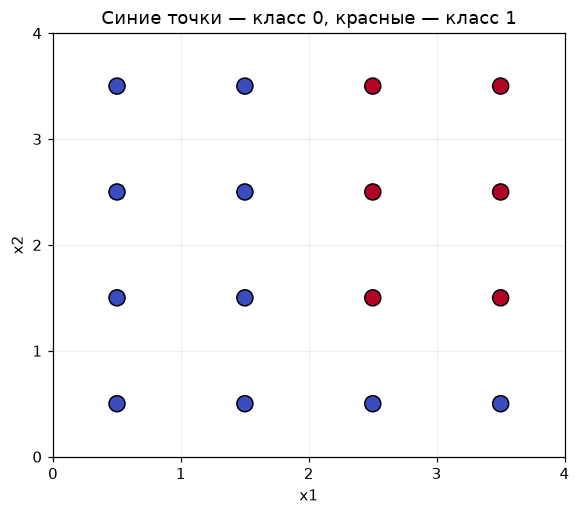

In [2]:
x1_values = np.array([0.5, 1.5, 2.5, 3.5])
x2_values = np.array([0.5, 1.5, 2.5, 3.5])
x1_grid, x2_grid = np.meshgrid(x1_values, x2_values)
X_toy = np.column_stack([x1_grid.ravel(), x2_grid.ravel()])
y_toy = ((X_toy[:, 0] > 2) & (X_toy[:, 1] > 1)).astype(int)

# Оформление одного графика.
plt.figure(figsize=(6, 5))
plt.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap='coolwarm', s=110, edgecolor='black')
plt.xlim(0, 4)
plt.ylim(0, 4)
plt.xticks([0, 1, 2, 3, 4])
plt.yticks([0, 1, 2, 3, 4])
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Синие точки — класс 0, красные — класс 1')
plt.grid(alpha=0.2)
plt.show()

### Разрезы вручную

Первый вопрос `x1 ≤ 2` отделяет 8 нулей слева. Справа остаются 6 единиц и 2 нуля; их разделяет второй вопрос `x2 ≤ 1`. Каждая полученная область — лист дерева.

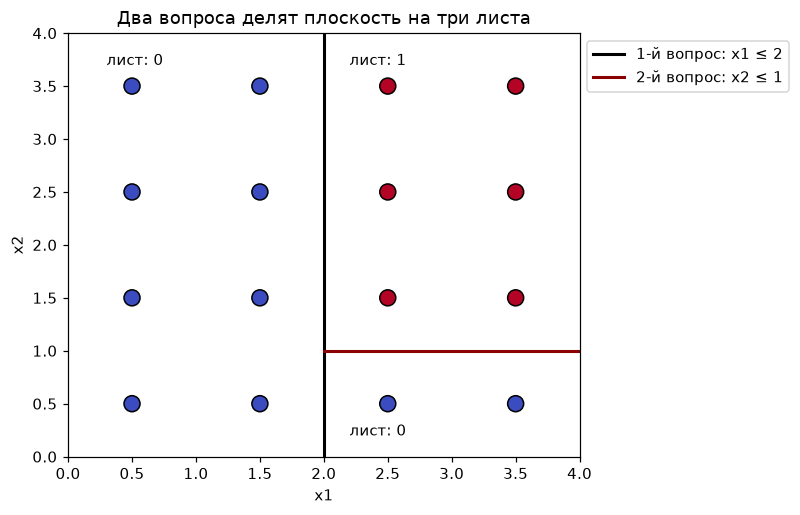

In [3]:
plt.figure(figsize=(6, 5))
plt.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap='coolwarm', s=110, edgecolor='black')
plt.axvline(2, color='black', linewidth=2, label='1-й вопрос: x1 ≤ 2')
plt.plot([2, 4], [1, 1], color='darkred', linewidth=2, label='2-й вопрос: x2 ≤ 1')
plt.text(0.3, 3.7, 'лист: 0')
plt.text(2.2, 0.2, 'лист: 0')
plt.text(2.2, 3.7, 'лист: 1')
plt.xlim(0, 4)
plt.ylim(0, 4)
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.title('Два вопроса делят плоскость на три листа')
plt.show()

### Как выбрать вопрос: Gini

Дерево ищет вопрос, после которого классы в новых группах **меньше перемешаны**. Для двух классов это можно измерить числом Gini:

$$G = 1-p_0^2-p_1^2,$$

где $p_0$ и $p_1$ — доли классов. Если в группе только один класс, $G=0$. Если классов поровну, $G=0{,}5$.

У наших 16 точек 10 нулей и 6 единиц: Gini ≈ 0.469. После разреза слева Gini = 0, справа = 0.375. У групп по 8 точек, поэтому среднее Gini после разреза = 0.188. Оно стало меньше: вопрос полезен. Алгоритм перебирает признаки и пороги, выбирая лучшее **уменьшение Gini** на текущем шаге. `criterion='entropy'` — другой способ измерить смешение; для начала достаточно Gini.

In [4]:
root_gini = 1 - (10 / 16) ** 2 - (6 / 16) ** 2
left_gini = 0
right_gini = 1 - (2 / 8) ** 2 - (6 / 8) ** 2
after_split = (8 / 16) * left_gini + (8 / 16) * right_gini
print('До вопроса:', round(root_gini, 3))
print('После вопроса:', round(after_split, 3))
print('Улучшение:', round(root_gini - after_split, 3))

До вопроса: 0.469
После вопроса: 0.188
Улучшение: 0.281


## 2. `DecisionTreeClassifier`: учим дерево

В узле картинки `samples` — число обучающих точек, `value` — сколько там нулей и единиц. `class` — ответ узла. Например, `value = [2, 6]` означает 2 нуля и 6 единиц. Порог `2.0` лежит между ближайшими координатами 1.5 и 2.5.

In [5]:
toy_tree = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
toy_tree.fit(X_toy, y_toy)
print(export_text(toy_tree, feature_names=['x1', 'x2']))
print('Предсказание для (3, 3):', toy_tree.predict([[3, 3]])[0])
print('Вероятности [класс 0, класс 1]:', toy_tree.predict_proba([[3, 3]])[0])

|--- x1 <= 2.00
|   |--- class: 0
|--- x1 >  2.00
|   |--- x2 <= 1.00
|   |   |--- class: 0
|   |--- x2 >  1.00
|   |   |--- class: 1

Предсказание для (3, 3): 1
Вероятности [класс 0, класс 1]: [0. 1.]


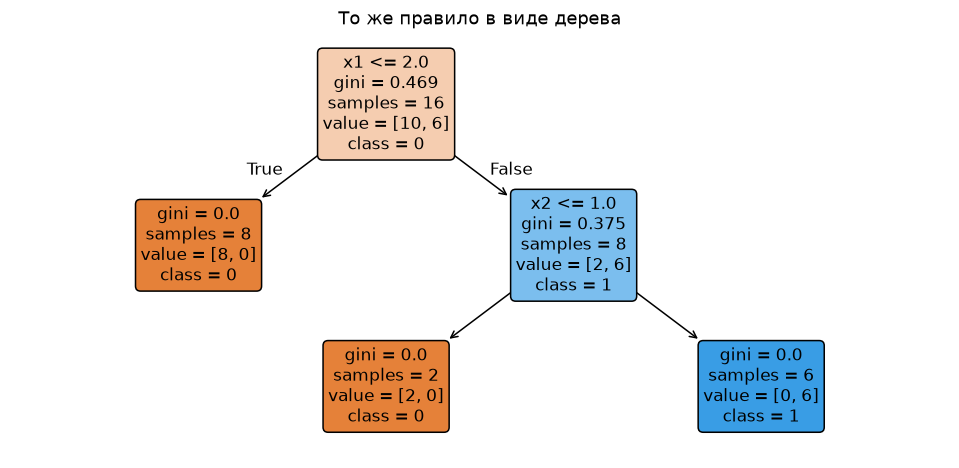

In [6]:
plt.figure(figsize=(11, 5))
plot_tree(toy_tree, feature_names=['x1', 'x2'], class_names=['0', '1'], filled=True, rounded=True, fontsize=11)
plt.title('То же правило в виде дерева')
plt.show()

### Как дерево делит всю плоскость

Создадим много точек сетки и спросим класс каждой. **Сетка нужна только для рисунка**, а не для обучения модели. Фон покажет, какой ответ получит новая точка в любой области.

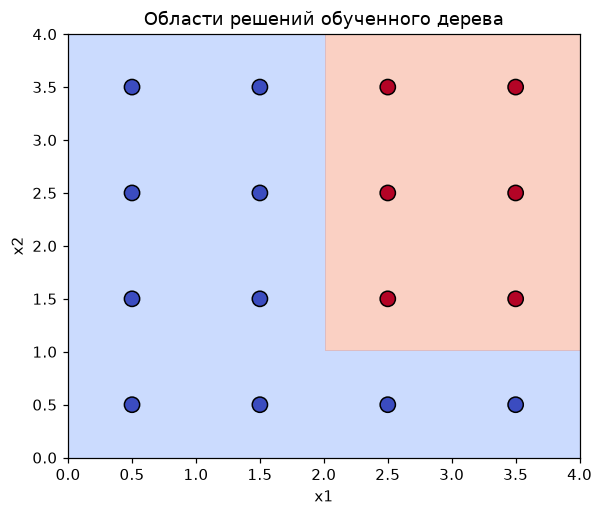

In [7]:
# Только для рисунка: сетка новых точек
grid_x1, grid_x2 = np.meshgrid(np.linspace(0, 4, 201), np.linspace(0, 4, 201))
grid_points = np.column_stack([grid_x1.ravel(), grid_x2.ravel()])
grid_prediction = toy_tree.predict(grid_points).reshape(grid_x1.shape)

plt.figure(figsize=(6, 5))
plt.contourf(grid_x1, grid_x2, grid_prediction, levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.45)
plt.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap='coolwarm', s=100, edgecolor='black')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Области решений обученного дерева')
plt.show()

### Сравнение с логистической регрессией

Логистическая регрессия проводит одну прямую границу. Наше правило требует двух вопросов. Поэтому на этих 16 обучающих точках дерево описывает правило точно, а одна прямая — нет. Это пример формы границ, не честная оценка качества на новых данных.

Правильных ответов на обучающих точках:
Дерево: 1.0 Логистическая: 0.875


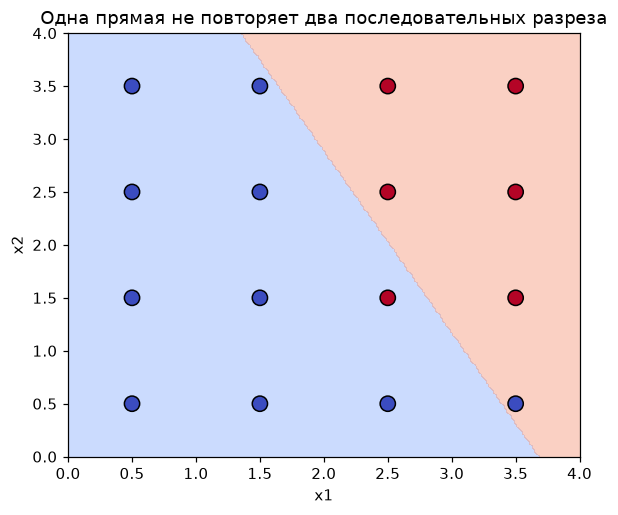

In [8]:
toy_linear = make_pipeline(StandardScaler(), LogisticRegression(C=10, random_state=RANDOM_STATE))
toy_linear.fit(X_toy, y_toy)
linear_region = toy_linear.predict(grid_points).reshape(grid_x1.shape)
print('Правильных ответов на обучающих точках:')
print('Дерево:', accuracy_score(y_toy, toy_tree.predict(X_toy)), 'Логистическая:', accuracy_score(y_toy, toy_linear.predict(X_toy)))

plt.figure(figsize=(6, 5))
plt.contourf(grid_x1, grid_x2, linear_region, levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.45)
plt.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap='coolwarm', s=100, edgecolor='black')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Одна прямая не повторяет два последовательных разреза')
plt.show()

**Проверьте себя:** `(3, 0.5)` получит класс 0, а `(3, 3)` — класс 1. `export_text` выше показывает путь вопрос за вопросом.

Для класса дерево хранит доли ответов в листе. Если там 7 единиц из 10 точек, `predict_proba` для класса 1 будет 0.7. В маленьком листе такая вероятность ненадёжна. Дереву не нужно масштабировать числа; текстовые категории для обычного дерева sklearn нужно закодировать числами.

## 3. `DecisionTreeRegressor`: дерево предсказывает число

В регрессии вопросы те же, но лист возвращает **среднее ответов** попавших в него точек. Для ответов `[10, 12, 14]` прогноз равен 12. Хороший разрез уменьшает ошибки относительно средних в новых листах; обычный критерий — `squared_error`.

В каждом листе одно число, поэтому прогноз дерева выглядит как ступеньки. За пределами изученных значений дерево не продолжит тренд прямой.

В следующей ячейке мы сами создаём точки для рисунка: базовый ответ 10, плюс 6 при `x1 > 2`, плюс 4 при `x2 > 2` и небольшой случайный шум. Код генерации заучивать не нужно; рабочие команды модели — `fit` и `predict`.

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
X_reg_toy = rng.uniform(0, 4, size=(180, 2))
y_reg_toy = 10 + 6 * (X_reg_toy[:, 0] > 2) + 4 * (X_reg_toy[:, 1] > 2) + rng.normal(0, 0.7, size=180)
reg_tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=RANDOM_STATE)
reg_tree.fit(X_reg_toy, y_reg_toy)
print(export_text(reg_tree, feature_names=['x1', 'x2']))
print('Прогноз для (3, 3):', round(reg_tree.predict([[3, 3]])[0], 2))

|--- x1 <= 1.99
|   |--- x2 <= 1.99
|   |   |--- x2 <= 0.72
|   |   |   |--- value: [10.35]
|   |   |--- x2 >  0.72
|   |   |   |--- value: [10.00]
|   |--- x2 >  1.99
|   |   |--- x1 <= 1.50
|   |   |   |--- value: [14.00]
|   |   |--- x1 >  1.50
|   |   |   |--- value: [13.55]
|--- x1 >  1.99
|   |--- x2 <= 1.99
|   |   |--- x2 <= 0.48
|   |   |   |--- value: [16.24]
|   |   |--- x2 >  0.48
|   |   |   |--- value: [15.72]
|   |--- x2 >  1.99
|   |   |--- x1 <= 3.18
|   |   |   |--- value: [20.24]
|   |   |--- x1 >  3.18
|   |   |   |--- value: [19.89]

Прогноз для (3, 3): 20.24


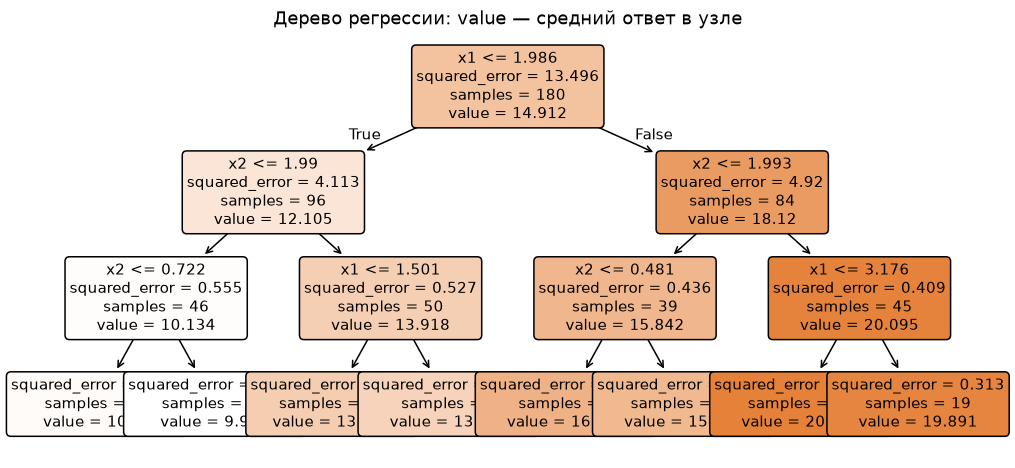

In [10]:
plt.figure(figsize=(11, 5))
plot_tree(reg_tree, feature_names=['x1', 'x2'], filled=True, rounded=True, fontsize=10)
plt.title('Дерево регрессии: value — средний ответ в узле')
plt.show()

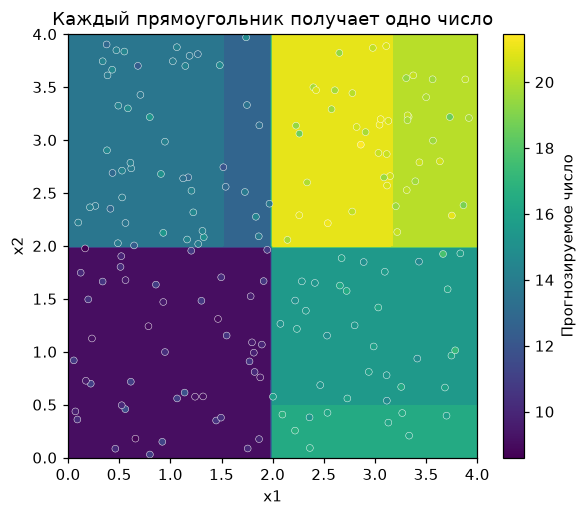

In [11]:
reg_grid_values = reg_tree.predict(grid_points).reshape(grid_x1.shape)
plt.figure(figsize=(6, 5))
plt.contourf(grid_x1, grid_x2, reg_grid_values, levels=12, cmap='viridis')
plt.scatter(X_reg_toy[:, 0], X_reg_toy[:, 1], c=y_reg_toy, cmap='viridis', s=20, edgecolor='white', linewidth=0.3)
plt.colorbar(label='Прогнозируемое число')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Каждый прямоугольник получает одно число')
plt.show()

### Слишком глубокое дерево запоминает шум

Если делить точки до очень маленьких листьев, ошибка на обучении может почти исчезнуть, а на новых данных вырасти. Это **переобучение**. Чаще всего начинают с двух ограничений:

| Параметр | Смысл |
|---|---|
| `max_depth` | Максимальное число вопросов на пути |
| `min_samples_leaf` | Минимальное число обучающих точек в листе |

`min_samples_split` задаёт минимум точек для дальнейшего разделения узла. Слишком строгие ограничения тоже вредят: дерево может не заметить настоящую зависимость. Выбирайте параметры по валидации, а не по обучающей ошибке.

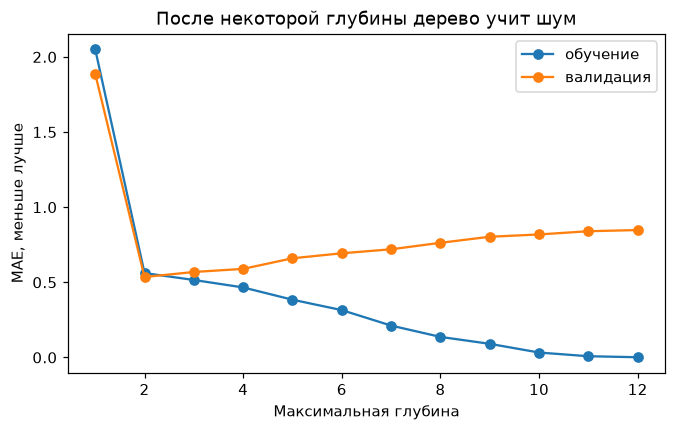

In [12]:
X_depth_train, X_depth_valid, y_depth_train, y_depth_valid = train_test_split(
    X_reg_toy, y_reg_toy, test_size=0.35, random_state=RANDOM_STATE
)
depths = list(range(1, 13))
train_errors = []
valid_errors = []
for depth in depths:
    current_tree = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE)
    current_tree.fit(X_depth_train, y_depth_train)
    train_errors.append(mean_absolute_error(y_depth_train, current_tree.predict(X_depth_train)))
    valid_errors.append(mean_absolute_error(y_depth_valid, current_tree.predict(X_depth_valid)))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_errors, marker='o', label='обучение')
plt.plot(depths, valid_errors, marker='o', label='валидация')
plt.xlabel('Максимальная глубина')
plt.ylabel('MAE, меньше лучше')
plt.title('После некоторой глубины дерево учит шум')
plt.legend()
plt.show()

На графике ошибка обучения обычно падает при росте глубины. Если ошибка валидации начала расти, дерево стало запоминать особенности обучающих строк. Конкретная «лучшая глубина» зависит от данных.

## 4. Бутстрапинг: тянем строки с возвращением

Есть карточки `[0, 1, 2, 3, 4]`. Тянем карточку, **возвращаем её**, затем тянем снова. За пять попыток может выйти `[3, 0, 3, 4, 0]`: номера 0 и 3 повторились, а 1 и 2 не попали. Такая выборка называется **бутстрап-выборкой**.

Для каждого дерева леса тянут из обучающих строк столько строк, сколько было изначально, но с повторами. В большой выборке обычно окажется около **63% различных строк**; остальные места занимают повторы. Не попавшие в конкретное дерево строки называют **OOB**. Бутстрап делают только после отделения теста.

Исходные номера: [ 0  1  2  3  4  5  6  7  8  9 10 11]
Бутстрап-выборка: [11  7  8 10  6  9 10  2  0  3  3 10]
Не попали (OOB): [1 4 5]


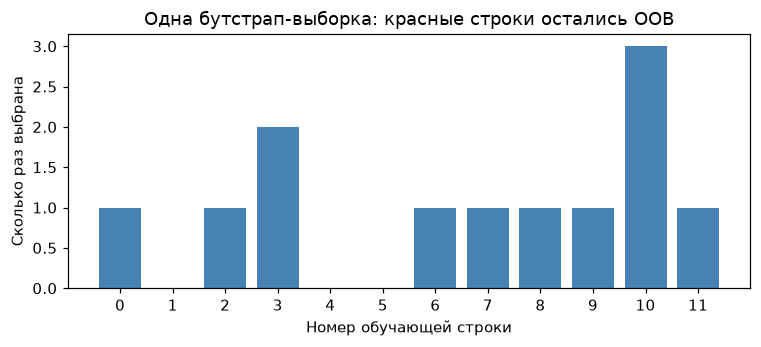

In [13]:
small_rng = np.random.default_rng(7)
original_ids = np.arange(12)
bootstrap_ids = small_rng.choice(original_ids, size=len(original_ids), replace=True)
counts = np.bincount(bootstrap_ids, minlength=len(original_ids))
oob_ids = original_ids[counts == 0]
print('Исходные номера:', original_ids)
print('Бутстрап-выборка:', bootstrap_ids)
print('Не попали (OOB):', oob_ids)

plt.figure(figsize=(8, 3))
plt.bar(original_ids, counts, color=['tomato' if count == 0 else 'steelblue' for count in counts])
plt.xticks(original_ids)
plt.xlabel('Номер обучающей строки')
plt.ylabel('Сколько раз выбрана')
plt.title('Одна бутстрап-выборка: красные строки остались OOB')
plt.show()

### Почему много деревьев лучше одного?

Дерево чувствительно к составу обучения. Разные бутстрап-выборки дают разные деревья. Усреднение их ошибок часто делает ответ устойчивее. В регрессии лес усредняет **числа** деревьев. В классификации sklearn усредняет их **вероятности классов**, затем выбирает класс с наибольшей средней вероятностью. Если деревья ошибаются одинаково, усреднение почти не поможет.

## 5. Случайный лес

Каждое дерево получает свою бутстрап-выборку. Кроме того, **на каждом узле** оно ищет вопрос лишь среди случайной части признаков. Это `max_features`. Так деревья меньше похожи друг на друга.

`n_estimators` — число деревьев. Больше деревьев обычно даёт более устойчивый ответ, но требует больше времени и памяти. `random_state` помогает повторить результат. Для олимпиадной таблицы начинайте с разумных ограничений `max_depth` и `min_samples_leaf`, затем проверяйте качество на валидации.

### Четыре модели

| Нужен ответ | Одно дерево | Много деревьев |
|---|---|---|
| Класс 0/1 | `DecisionTreeClassifier` | `RandomForestClassifier` |
| Число | `DecisionTreeRegressor` | `RandomForestRegressor` |

Шаблон одинаковый: создать модель → `fit(X_train, y_train)` → `predict(X_valid)`. У классификаторов есть `predict_proba(X_valid)`.

### Одно дерево и лес на двух координатах

Для рисунка создадим шумные двумерные данные. Сначала посмотрим ответ одного дерева из леса, затем ответ всего леса.

Код ниже создаёт точки и специально меняет несколько правильных классов, чтобы получился шум. Сетка снова нужна только для закрашивания фона.

In [14]:
moon_rng = np.random.default_rng(RANDOM_STATE)
X_plane = moon_rng.uniform(-3, 3, size=(300, 2))
y_plane = ((X_plane[:, 0] ** 2 + X_plane[:, 1] ** 2 < 4) | (X_plane[:, 0] > 1.5)).astype(int)
flips = moon_rng.choice(len(y_plane), size=18, replace=False)
y_plane[flips] = 1 - y_plane[flips]
plane_forest = RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=3, random_state=RANDOM_STATE)
plane_forest.fit(X_plane, y_plane)
plane_x1, plane_x2 = np.meshgrid(np.linspace(-3, 3, 201), np.linspace(-3, 3, 201))
plane_grid = np.column_stack([plane_x1.ravel(), plane_x2.ravel()])
first_tree_region = plane_forest.estimators_[0].predict(plane_grid).reshape(plane_x1.shape)
forest_region = plane_forest.predict(plane_grid).reshape(plane_x1.shape)

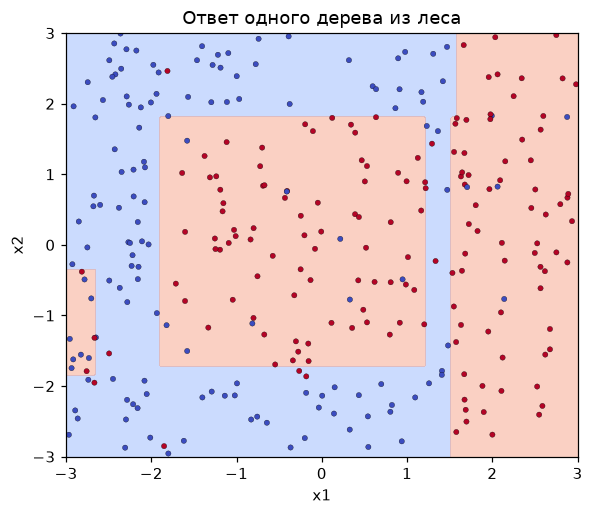

In [15]:
plt.figure(figsize=(6, 5))
plt.contourf(plane_x1, plane_x2, first_tree_region, levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.45)
plt.scatter(X_plane[:, 0], X_plane[:, 1], c=y_plane, cmap='coolwarm', s=12, edgecolor='black', linewidth=0.2)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Ответ одного дерева из леса')
plt.show()

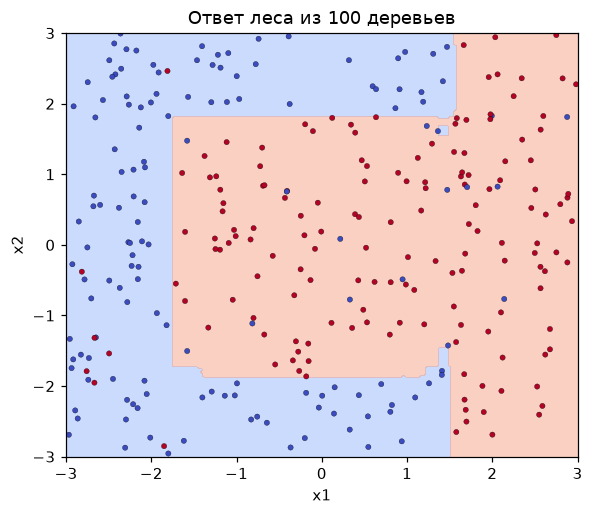

In [16]:
plt.figure(figsize=(6, 5))
plt.contourf(plane_x1, plane_x2, forest_region, levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.45)
plt.scatter(X_plane[:, 0], X_plane[:, 1], c=y_plane, cmap='coolwarm', s=12, edgecolor='black', linewidth=0.2)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Ответ леса из 100 деревьев')
plt.show()

И дерево, и лес проводят ступенчатые границы. Лес объединяет много разных разрезов. По красоте границы нельзя выбирать модель: нужна метрика на невидимых строках.

## 6. Классификация на настоящем наборе данных

Встроенный набор Breast Cancer Wisconsin содержит 30 числовых характеристик и два класса. Это учебное сравнение моделей. Отделяем 25% строк для **валидации до обучения**. Логистическую регрессию масштабируем через `Pipeline`: scaler вычисляет среднее и разброс только на train. Дереву и лесу масштаб не нужен.

Сравниваем `accuracy` и `F1`. При редком важном классе дополнительно смотрите precision и recall: высокая accuracy может скрыть пропущенные объекты.

Словарь моделей в коде позволяет обучить все три одинаковым циклом и вывести общую таблицу результатов.

In [17]:
cancer = load_breast_cancer(as_frame=True)
X_class = cancer.data
y_class = cancer.target
print('Размер:', X_class.shape)
print('Классы:', dict(zip([str(name) for name in cancer.target_names], [int(count) for count in np.bincount(y_class)])))
Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_class, y_class, test_size=0.25, stratify=y_class, random_state=RANDOM_STATE
)
classification_models = {
    'Логистическая': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    'Дерево': DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE),
    'Лес': RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE),
}
classification_rows = []
for name, model in classification_models.items():
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_valid)
    classification_rows.append({'Модель': name, 'Accuracy': accuracy_score(yc_valid, pred), 'F1': f1_score(yc_valid, pred)})
classification_results = pd.DataFrame(classification_rows).set_index('Модель')
print(classification_results.round(3))
print('Вероятность класса 1 у леса для первой строки валидации:', round(classification_models['Лес'].predict_proba(Xc_valid.iloc[[0]])[0, 1], 3))

Размер: (569, 30)
Классы: {'malignant': 212, 'benign': 357}
               Accuracy     F1
Модель                        
Логистическая     0.986  0.989
Дерево            0.930  0.944
Лес               0.958  0.967
Вероятность класса 1 у леса для первой строки валидации: 0.985


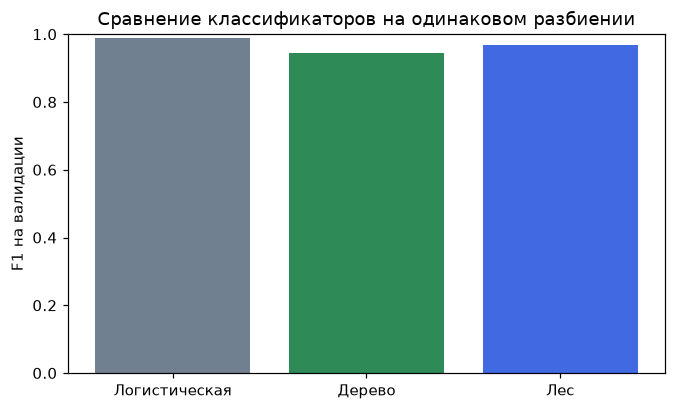

In [18]:
plt.figure(figsize=(7, 4))
plt.bar(classification_results.index, classification_results['F1'], color=['slategray', 'seagreen', 'royalblue'])
plt.ylim(0, 1)
plt.ylabel('F1 на валидации')
plt.title('Сравнение классификаторов на одинаковом разбиении')
plt.show()

В этом запуске логистическая регрессия получила F1 ≈ 0.989, лес ≈ 0.967, дерево ≈ 0.944. Сложная модель не обязана побеждать. Сравнение честное, потому что все три модели видели одни и те же строки обучения и валидации. В настоящей задаче параметры подбирайте на отдельной валидации, а отдельный test оставляйте для финальной оценки.

## 7. Регрессия на настоящем наборе данных

Встроенный набор Diabetes содержит числовые признаки и числовой ответ. Сравним линейную регрессию, дерево и лес на одинаковых строках обучения и валидации. **MAE** — средняя ошибка в единицах ответа; меньше лучше. **RMSE** сильнее реагирует на большие промахи. **R²** показывает, насколько прогноз лучше постоянного среднего; 1 — идеально, значение может быть отрицательным.

In [19]:
diabetes = load_diabetes(as_frame=True)
X_num = diabetes.data
y_num = diabetes.target
print('Размер:', X_num.shape)
Xr_train, Xr_valid, yr_train, yr_valid = train_test_split(
    X_num, y_num, test_size=0.25, random_state=RANDOM_STATE
)
regression_models = {
    'Линейная': LinearRegression(),
    'Дерево': DecisionTreeRegressor(max_depth=4, min_samples_leaf=10, random_state=RANDOM_STATE),
    'Лес': RandomForestRegressor(n_estimators=200, min_samples_leaf=4, random_state=RANDOM_STATE),
}
regression_rows = []
for name, model in regression_models.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_valid)
    regression_rows.append({
        'Модель': name,
        'MAE': mean_absolute_error(yr_valid, pred),
        'RMSE': np.sqrt(mean_squared_error(yr_valid, pred)),
        'R²': r2_score(yr_valid, pred),
    })
regression_results = pd.DataFrame(regression_rows).set_index('Модель')
print(regression_results.round(2))

Размер: (442, 10)
            MAE   RMSE    R²
Модель                      
Линейная  41.55  53.37  0.48
Дерево    44.42  55.19  0.45
Лес       42.40  53.52  0.48


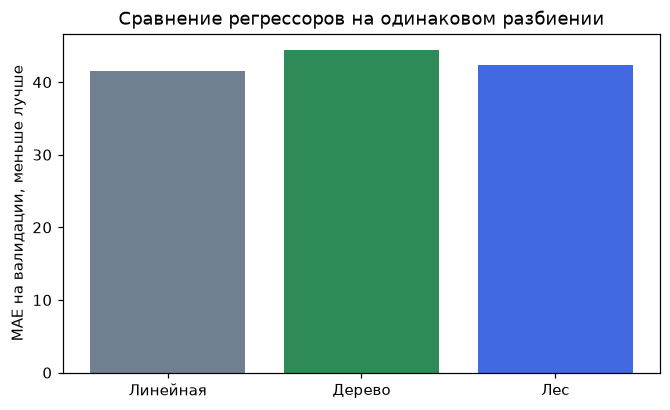

In [20]:
plt.figure(figsize=(7, 4))
plt.bar(regression_results.index, regression_results['MAE'], color=['slategray', 'seagreen', 'royalblue'])
plt.ylabel('MAE на валидации, меньше лучше')
plt.title('Сравнение регрессоров на одинаковом разбиении')
plt.show()

В этом запуске линейная регрессия получила немного меньшую MAE, чем лес (41.55 против 42.40). Выбор модели зависит от данных. Ниже диагональ означает идеальный прогноз; удаление точек от неё показывает размер ошибки леса.

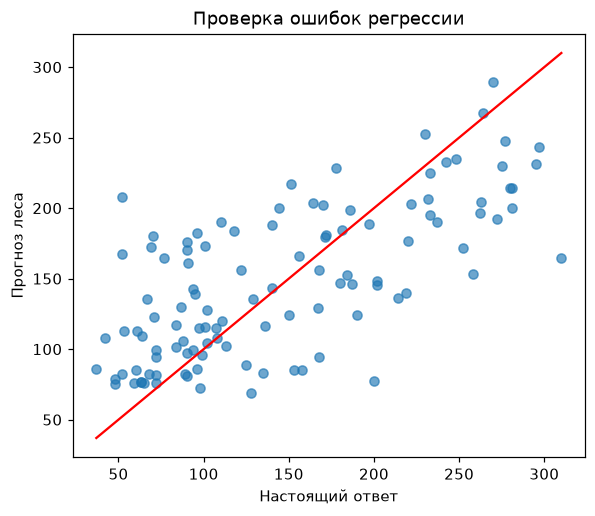

In [21]:
forest_reg_prediction = regression_models['Лес'].predict(Xr_valid)
plt.figure(figsize=(6, 5))
plt.scatter(yr_valid, forest_reg_prediction, alpha=0.65)
plt.plot([yr_valid.min(), yr_valid.max()], [yr_valid.min(), yr_valid.max()], color='red')
plt.xlabel('Настоящий ответ')
plt.ylabel('Прогноз леса')
plt.title('Проверка ошибок регрессии')
plt.show()

### Параметры леса, которые полезно знать

| Параметр | Что меняет |
|---|---|
| `n_estimators` | Число деревьев: больше — дольше и обычно устойчивее |
| `max_depth` | Максимальная глубина каждого дерева |
| `min_samples_leaf` | Минимальный размер листа; больший лист меньше учит шум |
| `max_features` | Сколько признаков проверять на одном узле |
| `bootstrap=True` | Строки дереву выбираются с возвращением |
| `random_state` | Повторяемость результата |
| `n_jobs=-1` | Использовать доступные ядра процессора |

Начните с `max_depth` и `min_samples_leaf`. Несколько разумных вариантов сравните на валидации; **не подбирайте их по test**.

## 8. Что помнить на олимпиаде

1. **Начните с простого ориентира:** среднее для регрессии, частый класс для классификации. Потом сравните с линейной моделью, деревом и лесом на одинаковом разбиении.
2. **Не допускайте утечки:** ID и признаки из будущего не должны попасть в `fit`; заполнение пропусков и кодирование обучайте на train. В обычном sklearn дереве текстовые категории надо закодировать; с пропусками надёжнее явно разобраться до обучения.
3. **Проверяйте подходящую метрику:** MAE/RMSE для числа; для редкого класса смотрите F1, precision и recall, а не только accuracy. `predict_proba` помогает менять порог классификации.
4. **Следите за переобучением:** маленькая ошибка train не означает хорошую модель. Подбирайте глубину и размер листа на валидации. Лес часто устойчивее одного дерева, но тоже может ошибаться.
5. **Не считайте важность причиной:** большой `feature_importances_` не доказывает причинную связь; утечка может выглядеть очень важной. Лес также плохо продолжает числовой тренд за диапазон изученных ответов.

## Проверьте себя

1. Почему условие `x1 ≤ 2` даёт вертикальную границу?
2. Что предскажет лист регрессии с ответами `[4, 7, 10]`? **7**.
3. Почему в бутстрап-выборке бывают повторы? Что такое OOB?
4. Зачем лес случайно выбирает признаки на каждом узле?
5. Что означает рост ошибки валидации при увеличении глубины?

```python
DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
DecisionTreeRegressor(max_depth=4, min_samples_leaf=5, random_state=42)
RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=42)
RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42)
```

### Источники и дальнейшее чтение

- [Руководство scikit-learn по деревьям](https://scikit-learn.org/stable/modules/tree.html).
- [Руководство scikit-learn по ансамблям и случайному лесу](https://scikit-learn.org/stable/modules/ensemble.html#forest).
- [Пример scikit-learn по OOB-ошибке](https://scikit-learn.org/stable/auto_examples/ensemble/plot_ensemble_oob.html).